In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix


In [2]:
df = pd.read_csv('../data/Meteorite_Landings.csv')
print(df.shape)
print(df.columns.tolist())
df.head()

(45716, 10)
['name', 'id', 'nametype', 'recclass', 'mass (g)', 'fall', 'year', 'reclat', 'reclong', 'GeoLocation']


,name,id,nametype,recclass,mass (g),fall,year,reclat,reclong,GeoLocation
0,Aachen,1,Valid,L5,21.0,Fell,1880.0,50.77500,6.08333,"(50.775, 6.08333)"
1,Aarhus,2,Valid,H6,720.0,Fell,1951.0,56.18333,10.23333,"(56.18333, 10.23333)"
2,Abee,6,Valid,EH4,107000.0,Fell,1952.0,54.21667,-113.00000,"(54.21667, -113.0)"
3,Acapulco,10,Valid,Acapulcoite,1914.0,Fell,1976.0,16.88333,-99.90000,"(16.88333, -99.9)"
4,Achiras,370,Valid,L6,780.0,Fell,1902.0,-33.16667,-64.95000,"(-33.16667, -64.95)"


In [3]:
df.isnull().sum()

name              0
id                0
nametype          0
recclass          0
mass (g)        131
fall              0
year            291
reclat         7315
reclong        7315
GeoLocation    7315
dtype: int64

In [4]:
df.duplicated(subset=['id']).sum()

np.int64(0)

In [5]:
df['no_coords'] = df['reclat'].isnull()
print(df.groupby('no_coords')['fall'].value_counts(normalize=True))
print(df['nametype'].value_counts())
print(df['year'].describe())
print("lat/long both 0:", ((df['reclat'] == 0) & (df['reclong'] == 0)).sum())

no_coords  fall 
False      Found    0.971433
           Fell     0.028567
True       Found    0.998633
           Fell     0.001367
Name: proportion, dtype: float64
nametype
Valid     45641
Relict       75
Name: count, dtype: int64
count    45425.000000
mean      1991.828817
std         25.052766
min        860.000000
25%       1987.000000
50%       1998.000000
75%       2003.000000
max       2101.000000
Name: year, dtype: float64
lat/long both 0: 6214


In [6]:
df_clean = df[df['nametype'] == 'Valid'].copy()
df_clean = df_clean.dropna(subset=['mass (g)', 'year', 'reclat', 'reclong'])
df_clean = df_clean[df_clean['mass (g)'] > 0]
df_clean = df_clean[df_clean['year'] <= 2026]
df_clean = df_clean[~((df_clean['reclat'] == 0) & (df_clean['reclong'] == 0))]

df_clean['fell'] = (df_clean['fall'] == 'Fell').astype(int)
df_clean['log_mass'] = np.log10(df_clean['mass (g)'])
df_clean['abs_lat'] = df_clean['reclat'].abs()

print(df_clean.shape)
print(df_clean['fell'].value_counts())

(31908, 14)
fell
0    30844
1     1064
Name: count, dtype: int64


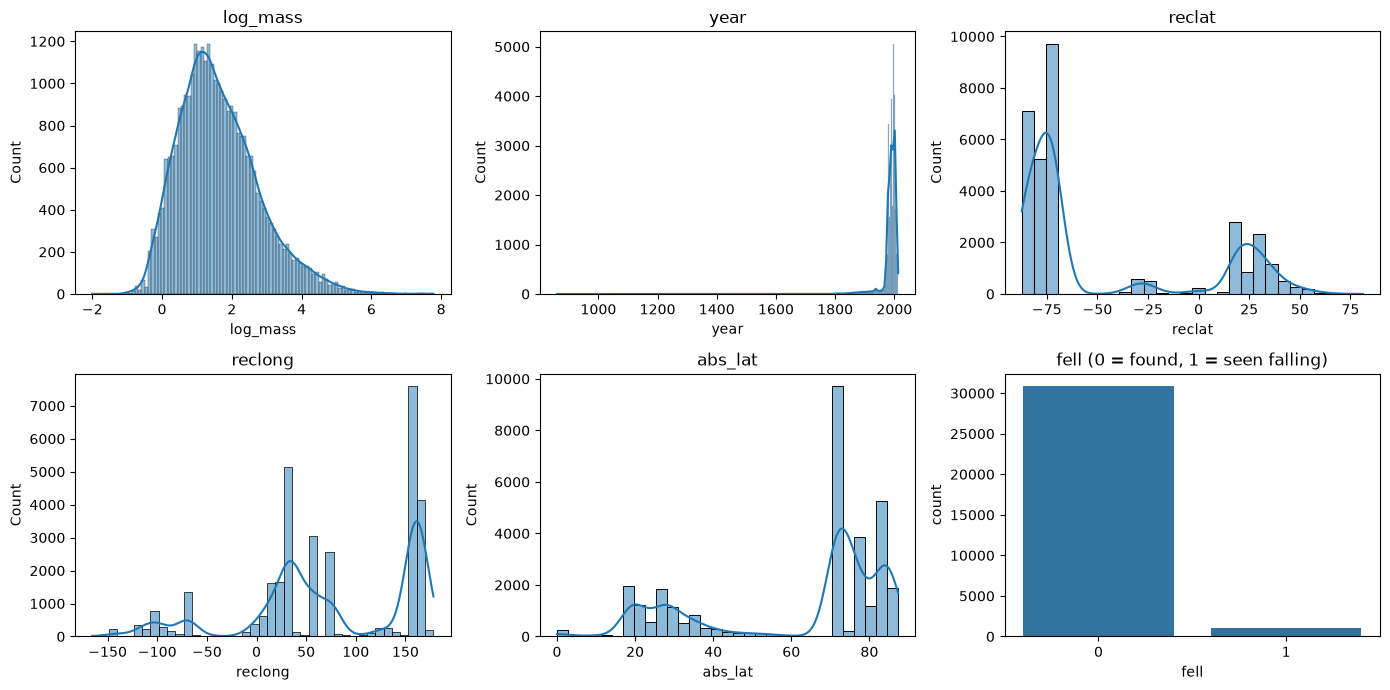

In [7]:
cols = ['log_mass', 'year', 'reclat', 'reclong', 'abs_lat']
fig, axes = plt.subplots(2, 3, figsize=(14, 7))

for ax, col in zip(axes.flat, cols):
    sns.histplot(df_clean[col], kde=True, ax=ax)
    ax.set_title(col)

sns.countplot(x='fell', data=df_clean, ax=axes.flat[5])
axes.flat[5].set_title('fell (0 = found, 1 = seen falling)')

plt.tight_layout()
plt.show()

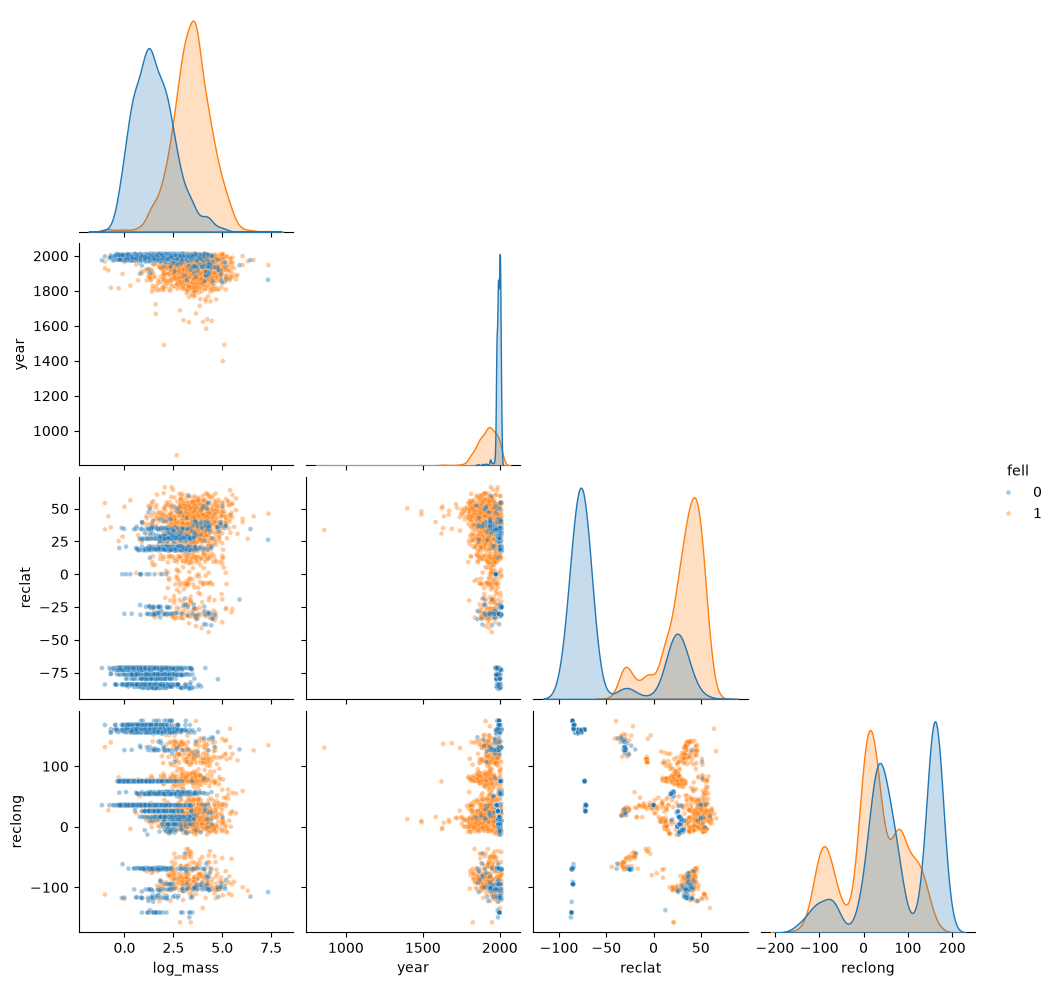

In [9]:
cols = ['log_mass', 'year', 'reclat', 'reclong']

plot_df = pd.concat([
    df_clean[df_clean['fell'] == 1],
    df_clean[df_clean['fell'] == 0].sample(2000, random_state=1)
])

sns.pairplot(plot_df[cols + ['fell']], hue='fell', corner=True,
             plot_kws={'alpha': 0.4, 's': 12},
             diag_kws={'common_norm': False})
plt.show()

In [16]:
features = ['log_mass', 'year', 'reclat', 'reclong']
X = df_clean[features]
y = df_clean['fell']

In [19]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)
scaler = StandardScaler()
X_tr = scaler.fit_transform(X_train)
X_te = scaler.transform(X_test)
model = LogisticRegression(class_weight='balanced', max_iter=2000, random_state=1)
model.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`

In [22]:
model.score(X_test, y_test)


0.9214979630209965

In [24]:
pred = model.predict(X_test)
proba = model.predict_proba(X_test)[:, 1]


In [29]:
print(classification_report(y_test, pred, target_names=['found', 'fell']))
print("ROC-AUC:", round(roc_auc_score(y_test, proba), 3))
print("Confusion matrix (rows = actual, cols = predicted):")
print(confusion_matrix(y_test, pred))
coefs = model.coef_[0]
print(pd.DataFrame({
    'feature': features,
    'coef': coefs.round(3),
    'odds_ratio': np.exp(coefs).round(3)
}))

              precision    recall  f1-score   support

       found       1.00      0.92      0.96      6172
        fell       0.29      0.93      0.44       210

    accuracy                           0.92      6382
   macro avg       0.64      0.93      0.70      6382
weighted avg       0.97      0.92      0.94      6382

ROC-AUC: 0.969
Confusion matrix (rows = actual, cols = predicted):
[[5685  487]
 [  14  196]]
    feature   coef  odds_ratio
0  log_mass  0.754       2.127
1      year -0.038       0.962
2    reclat  0.033       1.033
3   reclong  0.003       1.003
